# COM7022 Machine Learning — Fragrance Listing Segmentation

Student ID: `24205517`  
Dataset: `Sales-[5444].csv`

## A.1 Setup and data import

In [1]:
import re
import sys
import warnings
from pathlib import Path

import matplotlib
if 'get_ipython' not in globals():
    matplotlib.use('Agg')

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np
import pandas as pd
import seaborn as sns
import scipy
from scipy.cluster.hierarchy import cophenet, dendrogram, fcluster, linkage
from scipy.spatial.distance import pdist
from scipy.stats import kruskal
import sklearn
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.cluster import AgglomerativeClustering, DBSCAN, HDBSCAN, KMeans
from sklearn.decomposition import PCA
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (
    adjusted_rand_score,
    average_precision_score,
    calinski_harabasz_score,
    confusion_matrix,
    davies_bouldin_score,
    roc_auc_score,
    roc_curve,
    silhouette_samples,
    silhouette_score,
)
from sklearn.model_selection import KFold, StratifiedKFold, cross_val_predict, cross_val_score
from sklearn.neighbors import NearestNeighbors
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

try:
    get_ipython()
    from IPython.display import display
except NameError:
    def display(obj):
        print(obj.to_string() if hasattr(obj, 'to_string') else obj)

warnings.filterwarnings('ignore')
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 30)
sns.set_theme(style='whitegrid', context='notebook')

RS = 42  # fixed random seed for reproducibility
BASE_DIR = Path(__file__).resolve().parent if '__file__' in globals() else Path('.')
CHART_DIR = BASE_DIR / 'charts'
CHART_DIR.mkdir(parents=True, exist_ok=True)

FILE = next(iter(sorted(BASE_DIR.glob('Sales*5444*.csv'))), BASE_DIR / 'Sales-[5444].csv')
print(f'Python {sys.version.split()[0]} | numpy {np.__version__} | pandas {pd.__version__} | '
      f'scikit-learn {sklearn.__version__} | scipy {scipy.__version__}')
print('Data file:', FILE.name)

Python 3.11.11 | numpy 2.4.6 | pandas 3.1.0 | scikit-learn 1.9.1 | scipy 1.17.1
Data file: Sales-[5444].csv


## A.2 Data audit

In [2]:
raw = pd.read_csv(FILE)
print('Raw shape:', raw.shape)
display(raw.head())

audit = pd.DataFrame({
    'dtype': raw.dtypes.astype(str),
    'missing': raw.isna().sum(),
    'missing_%': (raw.isna().mean() * 100).round(1),
    'unique': raw.nunique(),
})
display(audit)

print('Fully duplicated rows:', raw.duplicated().sum(),
      '| duplicated product descriptions:', raw.details.duplicated().sum())
dup = raw[raw.details.duplicated(keep=False)].groupby('details').agg(
    prices=('price', 'nunique'),
    locations=('itemLocation', 'nunique'),
)
print(f'{len(dup)} descriptions are repeated; {(dup.prices > 1).mean():.1%} differ in price and '
      f'{(dup.locations > 1).mean():.1%} differ in seller location')

Raw shape: (1000, 10)


,Item_Name,details,Catatory,price,priceWithCurrency,available,text,sold,lastUpdated,itemLocation
0,Dior,Christian Dior Sauvage Men's EDP 3.4 oz Fragra...,Eau de Parfum,84.99,US $84.99/ea,10.0,More than 10 available / 116 sold,NaN,"May 24, 2024 10:03:04 PDT","Allen Park, Michigan, United States"
1,AS SHOW,A-v-entus Eau de Parfum 3.3 oz 100ML Millesime...,Eau de Parfum,NaN,US $109.99,8.0,8 available / 48 sold,48.0,"May 23, 2024 23:07:49 PDT","Atlanta, Georgia, Canada"
2,Unbranded,HOGO BOSS cologne For Men 3.4 oz,Eau de Toilette,100.00,US $100.00,10.0,More than 10 available / 27 sold,27.0,"May 22, 2024 21:55:43 PDT","Dearborn, Michigan, United States"
3,Giorgio Armani,Acqua Di Gio by Giorgio Armani 6.7 Fl oz Eau D...,Eau de Toilette,NaN,US $44.99/ea,2.0,2 available / 159 sold,159.0,"May 24, 2024 03:30:43 PDT","Reinholds, Pennsylvania, United States"
4,Lattafa,Lattafa Men's Hayaati Al Maleky EDP Spray 3.4 ...,Fragrances,16.91,NaN,NaN,Limited quantity available / 156 sold,NaN,"May 24, 2024 07:56:25 PDT","Brooklyn, New York, United States"


,dtype,missing,missing_%,unique
Item_Name,str,1,0.1,246
details,str,0,0.0,966
Catatory,str,3,0.3,63
price,float64,5,0.5,600
priceWithCurrency,str,1,0.1,684
available,float64,111,11.1,89
text,str,3,0.3,758
sold,float64,8,0.8,428
lastUpdated,str,53,5.3,933
itemLocation,str,0,0.0,276


Fully duplicated rows: 0 | duplicated product descriptions: 34
27 descriptions are repeated; 88.9% differ in price and 88.9% differ in seller location


## A.3 Data cleaning and recovery

In [3]:
df = raw.copy()
log = {}

# 1. Price: recover missing entries from priceWithCurrency, then convert CAD -> USD
price_from_str = df['priceWithCurrency'].str.extract(r'([\d,]+\.?\d*)')[0].str.replace(',', '').astype(float)
log['price recovered from priceWithCurrency'] = int(df.price.isna().sum() - df.price.fillna(price_from_str).isna().sum())
price = df.price.fillna(price_from_str)
is_cad = df['priceWithCurrency'].fillna('').str.startswith('C $')
CAD_USD = 0.73  # assumed May-2024 exchange rate (checked via sensitivity in A.9)
df['price_usd'] = np.where(is_cad, price * CAD_USD, price)
log['prices converted CAD->USD'] = int(is_cad.sum())

# 2. Units sold: recover missing numeric entries from listing text ("n sold")
sold_from_text = df.text.fillna('').str.extract(r'/ ([\d,]+) sold')[0].str.replace(',', '').astype(float)
log['sold recovered from text'] = int((df.sold.isna() & sold_from_text.notna()).sum())
df['sold_c'] = df.sold.fillna(sold_from_text)

# 3. Stock: map availability text onto a 1-10 ordinal scale (eBay display caps at 10)
t = df.text.fillna('')
stock = t.str.extract(r'^(?:More than )?(\d+)(?: lots)? available')[0].astype(float)
stock = np.where(t.str.startswith('Last One'), 1, stock)
stock = np.where(t.str.startswith('Limited'), 2, stock)
df['stock'] = np.minimum(pd.Series(stock, index=df.index), 10)
df['stock'] = df['stock'].fillna(np.minimum(df.available, 10))
log['stock recovered from text (was NaN in available)'] = int(raw.available.isna().sum() - df.stock.isna().sum())

# 4. Pack size (ml): parse ml or fl oz from product description (1 fl oz = 29.5735 ml)
d = df.details.fillna('')
ml = d.str.extract(r'(\d+(?:\.\d+)?)\s*ml\b', flags=re.I)[0].astype(float)
oz = d.str.extract(r'(\d+(?:\.\d+)?)\s*(?:fl\.?\s*)?oz\b', flags=re.I)[0].astype(float)
df['volume_ml'] = ml.fillna(oz * 29.5735)

# 5. Listing recency: hours elapsed since the newest listing update
ts = pd.to_datetime(
    df.lastUpdated.str.replace(r'\s[A-Z]{3}$', '', regex=True),
    format='%B %d, %Y %H:%M:%S',
    errors='coerce',
)
df['hours_since'] = (ts.max() - ts).dt.total_seconds() / 3600

# Audit missingness mechanism on raw lastUpdated (MNAR check)
lu_blank = df.lastUpdated.isna()
mnar_sold_missing_ts = round(float(df.loc[lu_blank, 'sold_c'].median()), 1)
mnar_sold_present_ts = round(float(df.loc[~lu_blank, 'sold_c'].median()), 1)
print(f'MNAR check - raw lastUpdated missing ({lu_blank.sum()} rows) median sold: '
      f'{mnar_sold_missing_ts:.1f} vs present: {mnar_sold_present_ts:.1f}')

# 6. Product type: consolidate 63 raw spellings (column named 'Catatory' in source) into 3 groups
c = df.Catatory.fillna('').str.lower()
df['product_type'] = np.select(
    [
        c.str.contains('toil'),
        c.str.contains('cologne|aftershave'),
        c.str.contains('parfum|perfume') & ~c.str.contains('toil'),
        c.str.contains('fragrance'),
    ],
    ['EDT', 'Cologne', 'EDP/Parfum', 'Fragrance'],
    default='Other',
)
df['product_type'] = df['product_type'].replace({'Cologne': 'Other', 'Fragrance': 'Other'})

# 7. Seller location: binary US vs international dispatch flag
country = df.itemLocation.str.split(',').str[-1].str.strip()
df['international'] = (country != 'United States').astype(float)

# 8. Brand: standardise casing/spacing, then frequency-encode (246 raw brand levels)
b = df.Item_Name.fillna('unknown').str.lower().str.replace(r'\s*&\s*', ' & ', regex=True).str.strip()
b = b.replace({'polo ralph lauren': 'ralph lauren'})
df['brand'] = b
df['brand_listings'] = b.map(b.value_counts())

# Drop listings lacking core price, sales, or stock values
before = len(df)
df = df.dropna(subset=['price_usd', 'sold_c', 'stock']).reset_index(drop=True)
dropped_rows = before - len(df)
log['rows dropped (missing price/sold/stock)'] = dropped_rows
print(f'Rows dropped: {dropped_rows} -> {len(df)} listings remain')

# Preserve pre-imputation copies so supervised CV fits capping/imputation strictly per fold
df['volume_ml_raw'] = df['volume_ml']
df['hours_since_raw'] = df['hours_since']
missing_vol_after_drop = int(df.volume_ml.isna().sum())
missing_hrs_after_drop = int(df.hours_since.isna().sum())
print(f'Missing before imputation -> volume_ml: {missing_vol_after_drop} | hours_since: {missing_hrs_after_drop}')

# Cap extreme multi-bottle bundles at the 99th percentile and median-impute remaining gaps
vol_q99 = float(df.volume_ml.quantile(0.99))
df['volume_ml'] = df.volume_ml.clip(upper=vol_q99)
df['volume_ml'] = df.volume_ml.fillna(df.volume_ml.median())
df['hours_since'] = df.hours_since.fillna(df.hours_since.median())
print('Remaining nulls in modelling features:',
      int(df[['price_usd', 'sold_c', 'stock', 'volume_ml', 'hours_since', 'brand_listings']].isna().sum().sum()))

# Verify why title gender was rejected (~80% men's fragrances -> near-constant flag)
men_share = float(df.details.str.contains(r'\bmen\b|\bman\b|\bhomme\b|\bfor men\b|\bmale\b', case=False, na=False).mean())
print(f'Share of titles referencing men: {men_share:.1%} (rejected for low variance)')

display(pd.Series(log, name='rows_affected').to_frame())

MNAR check - raw lastUpdated missing (53 rows) median sold: 5.0 vs present: 60.0
Rows dropped: 6 -> 994 listings remain
Missing before imputation -> volume_ml: 61 | hours_since: 116
Remaining nulls in modelling features: 0
Share of titles referencing men: 80.2% (rejected for low variance)


,rows_affected
price recovered from priceWithCurrency,5
prices converted CAD->USD,3
sold recovered from text,2
stock recovered from text (was NaN in available),108
rows dropped (missing price/sold/stock),6


## A.4 Descriptive statistics, transformations, and feature scaling

,feature,mean,sd,median,iqr,min,max,skew_raw,skew_after
0,Price (US$),46.13,34.78,35.70,36.00,3.0,259.09,1.97,0.09
1,Units Sold,773.96,3208.33,50.00,309.50,1.0,54052.00,9.72,0.54
2,Stock Level (1-10),6.90,3.37,8.00,7.00,1.0,10.00,-0.45,-0.45
3,Pack Size (ml),99.00,40.66,100.55,0.58,0.8,201.10,0.02,-2.92
4,Hours Since Update,78.16,110.55,36.89,73.58,0.0,552.50,2.25,-0.31
5,Brand Presence,19.12,19.03,11.00,30.00,1.0,60.00,0.93,-0.09


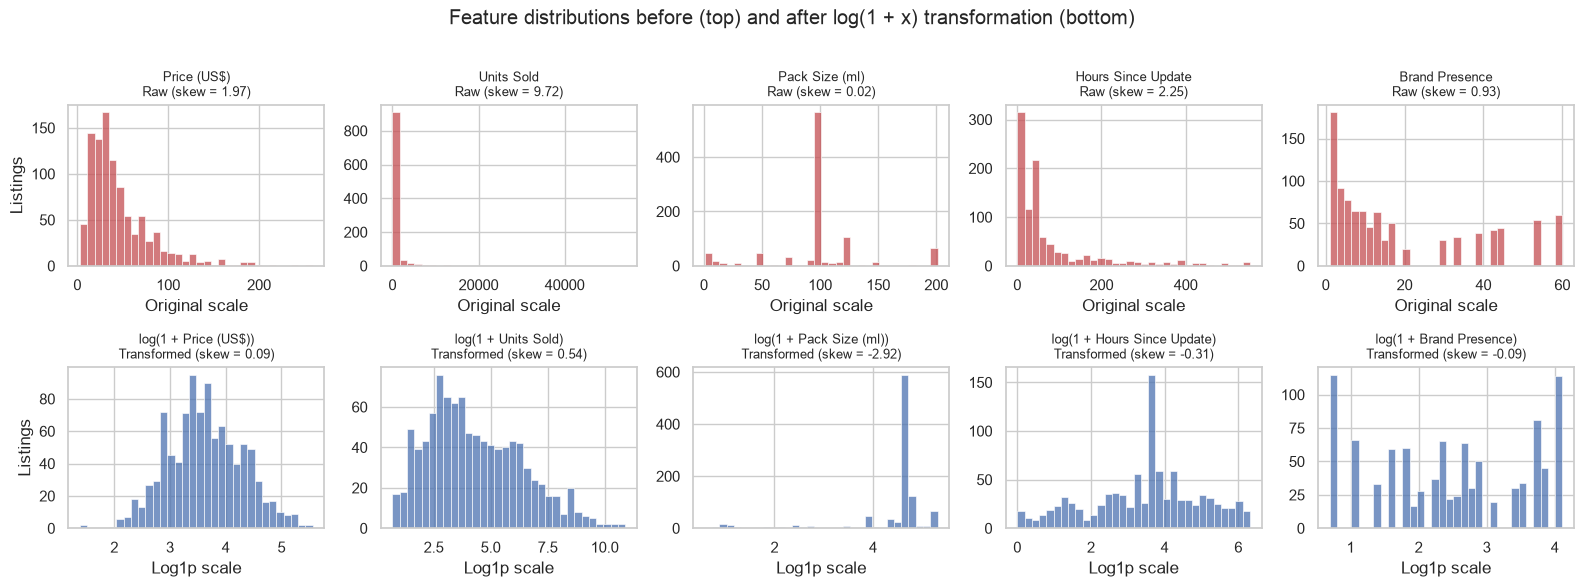

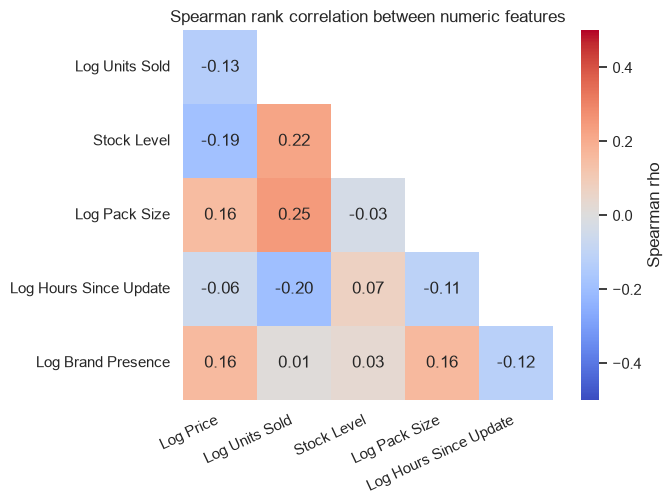

Max z-score if binary flags are standardised: {'product_type_EDP/Parfum': np.float64(1.24), 'product_type_EDT': np.float64(1.08), 'product_type_Other': np.float64(2.41), 'international': np.float64(3.21)}
dummies_0_1        -> international share per cluster: [0.05, 0.01, 0.12, 0.16, 0.0] | "Other" type share: [0.17, 0.09, 0.24, 0.09, 0.11]
dummies_z_scored   -> international share per cluster: [0.0, 0.0, 1.0, 0.0, 0.0] | "Other" type share: [0.0, 0.0, 0.07, 0.05, 1.0]
Final clustering matrix shape: (994, 10)


In [4]:
num_cols = ['price_usd', 'sold_c', 'stock', 'volume_ml', 'hours_since', 'brand_listings']
num_labels = {
    'price_usd': 'Price (US$)',
    'sold_c': 'Units Sold',
    'stock': 'Stock Level (1-10)',
    'volume_ml': 'Pack Size (ml)',
    'hours_since': 'Hours Since Update',
    'brand_listings': 'Brand Presence',
}

feat = pd.DataFrame({
    'log_price': np.log1p(df.price_usd),
    'log_sold': np.log1p(df.sold_c),
    'stock': df.stock,
    'log_volume': np.log1p(df.volume_ml),
    'log_hours': np.log1p(df.hours_since),
    'log_brand_listings': np.log1p(df.brand_listings),
})

feat_map = {
    'price_usd': 'log_price',
    'sold_c': 'log_sold',
    'stock': 'stock',
    'volume_ml': 'log_volume',
    'hours_since': 'log_hours',
    'brand_listings': 'log_brand_listings',
}

summary_rows = []
for col in num_cols:
    s = df[col]
    tf_col = feat_map[col]
    summary_rows.append({
        'feature': num_labels[col],
        'mean': round(float(s.mean()), 2),
        'sd': round(float(s.std()), 2),
        'median': round(float(s.median()), 2),
        'iqr': round(float(s.quantile(0.75) - s.quantile(0.25)), 2),
        'min': round(float(s.min()), 2),
        'max': round(float(s.max()), 2),
        'skew_raw': round(float(s.skew()), 2),
        'skew_after': round(float(feat[tf_col].skew()), 2),
    })
summary_df = pd.DataFrame(summary_rows)
display(summary_df)

# Chart 1: All five log-transformed variables before (top) and after log1p (bottom)
trans_pairs = [
    ('price_usd', 'log_price', 'Price (US$)'),
    ('sold_c', 'log_sold', 'Units Sold'),
    ('volume_ml', 'log_volume', 'Pack Size (ml)'),
    ('hours_since', 'log_hours', 'Hours Since Update'),
    ('brand_listings', 'log_brand_listings', 'Brand Presence'),
]
fig, axes = plt.subplots(2, 5, figsize=(16, 5.8))
for j, (raw_c, log_c, label) in enumerate(trans_pairs):
    sns.histplot(df[raw_c], bins=32, ax=axes[0, j], color='C3')
    axes[0, j].set_title(f'{label}\nRaw (skew = {df[raw_c].skew():.2f})', fontsize=9.5)
    axes[0, j].set_xlabel('Original scale')
    axes[0, j].set_ylabel('Listings' if j == 0 else '')

    sns.histplot(feat[log_c], bins=32, ax=axes[1, j], color='C0')
    axes[1, j].set_title(f'log(1 + {label})\nTransformed (skew = {feat[log_c].skew():.2f})', fontsize=9.5)
    axes[1, j].set_xlabel('Log1p scale')
    axes[1, j].set_ylabel('Listings' if j == 0 else '')
fig.suptitle('Feature distributions before (top) and after log(1 + x) transformation (bottom)', y=1.01)
fig.tight_layout()
fig.savefig(CHART_DIR / '01_log_transforms.png', dpi=200, bbox_inches='tight')
plt.show()
plt.close(fig)

# Chart 2: Lower-triangle Spearman correlation heatmap
corr = feat.corr(method='spearman')
pretty_feat = ['Log Price', 'Log Units Sold', 'Stock Level', 'Log Pack Size', 'Log Hours Since Update', 'Log Brand Presence']
corr.index = pretty_feat
corr.columns = pretty_feat
corr_sub = corr.iloc[1:, :-1]
mask = np.triu(np.ones_like(corr_sub, dtype=bool), k=1)

fig, ax = plt.subplots(figsize=(7.2, 5.2))
sns.heatmap(
    corr_sub,
    mask=mask,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0,
    vmin=-0.5,
    vmax=0.5,
    square=True,
    cbar_kws={'label': 'Spearman rho'},
    ax=ax,
)
ax.grid(False)
ax.set_title('Spearman rank correlation between numeric features')
plt.xticks(rotation=25, ha='right')
plt.yticks(rotation=0)
fig.tight_layout()
fig.savefig(CHART_DIR / '02_spearman_corr.png', dpi=200, bbox_inches='tight')
plt.show()
plt.close(fig)

# Scaling and categorical encoding experiment (0/1 flags vs z-scored flags)
dummies = pd.get_dummies(df[['product_type']]).astype(float)
dummies['international'] = df.international.values
X_num = StandardScaler().fit_transform(feat)
X = np.hstack([X_num, dummies.values])
X_alt = StandardScaler().fit_transform(np.hstack([feat.values, dummies.values]))
cols = list(feat.columns) + list(dummies.columns)

pretty_all = pretty_feat + ['Product: EDP/Parfum', 'Product: EDT', 'Product: Other', 'International Seller']

print('Max z-score if binary flags are standardised:',
      dict(zip(dummies.columns, np.round(X_alt[:, 6:].max(axis=0), 2))))
scaling_check = {}
for name, M in [('dummies_0_1', X), ('dummies_z_scored', X_alt)]:
    lab = KMeans(5, n_init=20, random_state=RS).fit_predict(M)
    intl = pd.Series(dummies.international.values).groupby(lab).mean().round(2).tolist()
    oth = pd.Series(dummies['product_type_Other'].values).groupby(lab).mean().round(2).tolist()
    scaling_check[name] = {'intl_shares': intl, 'other_shares': oth}
    print(f'{name:18s} -> international share per cluster: {intl} | "Other" type share: {oth}')
print('Final clustering matrix shape:', X.shape)

## A.5 Exploratory supervised checks (leak-free 5-fold cross-validation)

,task,model,primary_metric,primary_sd,secondary_metric
0,Regression,Baseline (mean),-0.003,0.002,2.069
1,Regression,Linear regression,0.182,0.049,1.866
2,Regression,Random forest regressor,0.299,0.046,1.728


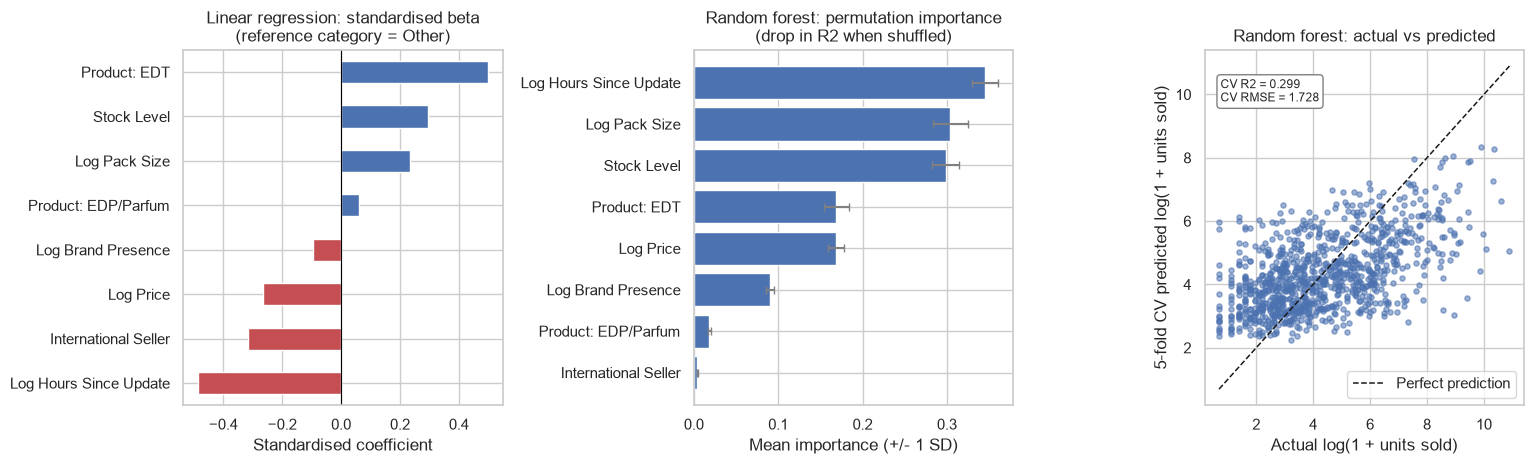

Top-seller threshold: 323.5 units sold | positive share: 25.1%


,task,model,accuracy,f1,roc_auc,pr_auc
0,Classification,Baseline (majority),0.750,0.000,0.500,0.250
1,Classification,Logistic regression,0.774,0.327,0.727,0.496
2,Classification,Random forest classifier,0.787,0.415,0.790,0.587


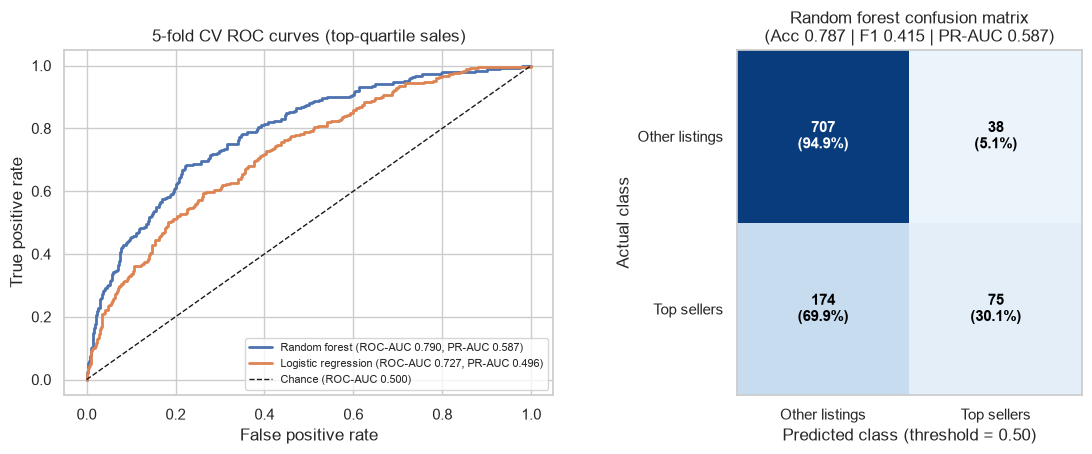

In [5]:
class PercentileClipper(BaseEstimator, TransformerMixin):
    """Clip a single column at its training-fold upper quantile to prevent CV leakage."""

    def __init__(self, col_idx=2, q=0.99):
        self.col_idx = col_idx
        self.q = q

    def fit(self, X_arr, y=None):
        self.upper_ = float(np.nanquantile(X_arr[:, self.col_idx], self.q))
        return self

    def transform(self, X_arr):
        Xc = X_arr.copy()
        Xc[:, self.col_idx] = np.clip(Xc[:, self.col_idx], None, self.upper_)
        return Xc


# Use drop-first dummy encoding (Product: Other as reference) so linear models are full-rank
X_sup = pd.DataFrame({
    'Log Price': np.log1p(df.price_usd),
    'Stock Level': df.stock,
    'Log Pack Size': np.log1p(df.volume_ml_raw),
    'Log Hours Since Update': np.log1p(df.hours_since_raw),
    'Log Brand Presence': np.log1p(df.brand_listings),
    'Product: EDT': (df.product_type == 'EDT').astype(float),
    'Product: EDP/Parfum': (df.product_type == 'EDP/Parfum').astype(float),
    'International Seller': df.international.values,
})
X_sup_arr = X_sup.to_numpy()
sup_names = list(X_sup.columns)
y_reg = np.log1p(df.sold_c).to_numpy()

kf = KFold(5, shuffle=True, random_state=RS)
reg_models = {
    'Baseline (mean)': DummyRegressor(),
    'Linear regression': make_pipeline(PercentileClipper(2, 0.99), SimpleImputer(strategy='median'), StandardScaler(), LinearRegression()),
    'Random forest regressor': make_pipeline(PercentileClipper(2, 0.99), SimpleImputer(strategy='median'), RandomForestRegressor(300, min_samples_leaf=5, random_state=RS, n_jobs=-1)),
}

reg_rows = []
for name, model in reg_models.items():
    r2_scores = cross_val_score(model, X_sup_arr, y_reg, cv=kf, scoring='r2')
    rmse_scores = -cross_val_score(model, X_sup_arr, y_reg, cv=kf, scoring='neg_root_mean_squared_error')
    reg_rows.append({
        'task': 'Regression',
        'model': name,
        'primary_metric': round(float(r2_scores.mean()), 3),
        'primary_sd': round(float(r2_scores.std()), 3),
        'secondary_metric': round(float(rmse_scores.mean()), 3),
    })
reg_tab = pd.DataFrame(reg_rows)
display(reg_tab)

lin_pipe = reg_models['Linear regression'].fit(X_sup_arr, y_reg)
rf_pipe = reg_models['Random forest regressor'].fit(X_sup_arr, y_reg)
coef = pd.Series(lin_pipe[-1].coef_, index=sup_names).sort_values()
perm = permutation_importance(rf_pipe, X_sup_arr, y_reg, n_repeats=15, random_state=RS, n_jobs=-1)
perm_order = np.argsort(perm.importances_mean)
pred_reg = cross_val_predict(reg_models['Random forest regressor'], X_sup_arr, y_reg, cv=kf)

# Chart 3: Regression coefficients, permutation importance, and actual vs CV predicted
fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.8))
coef.plot.barh(ax=axes[0], color=np.where(coef > 0, 'C0', 'C3'))
axes[0].axvline(0, color='black', lw=0.8)
axes[0].set_title('Linear regression: standardised beta\n(reference category = Other)')
axes[0].set_xlabel('Standardised coefficient')

axes[1].barh(
    [sup_names[i] for i in perm_order],
    perm.importances_mean[perm_order],
    xerr=perm.importances_std[perm_order],
    color='C0',
    ecolor='grey',
    capsize=3,
)
axes[1].set_title('Random forest: permutation importance\n(drop in R2 when shuffled)')
axes[1].set_xlabel('Mean importance (+/- 1 SD)')

axes[2].scatter(y_reg, pred_reg, s=14, alpha=0.55, color='C0')
lims = [float(y_reg.min()), float(y_reg.max())]
axes[2].plot(lims, lims, 'k--', lw=1.1, label='Perfect prediction')
axes[2].set_xlabel('Actual log(1 + units sold)')
axes[2].set_ylabel('5-fold CV predicted log(1 + units sold)')
axes[2].set_title('Random forest: actual vs predicted')
rf_r2_val = reg_rows[2]['primary_metric']
rf_rmse_val = reg_rows[2]['secondary_metric']
axes[2].text(
    0.05, 0.92,
    f'CV R2 = {rf_r2_val:.3f}\nCV RMSE = {rf_rmse_val:.3f}',
    transform=axes[2].transAxes,
    va='top',
    fontsize=8.5,
    bbox=dict(boxstyle='round,pad=0.3', facecolor='white', edgecolor='grey'),
)
axes[2].legend(loc='lower right')
fig.tight_layout()
fig.savefig(CHART_DIR / '03_regression_diagnostics.png', dpi=200, bbox_inches='tight')
plt.show()
plt.close(fig)

# Classification: top-quartile units sold (>= 324 units)
thr = float(df.sold_c.quantile(0.75))
y_clf = (df.sold_c >= thr).astype(int).to_numpy()
print(f'Top-seller threshold: {thr:.1f} units sold | positive share: {y_clf.mean():.1%}')

sk = StratifiedKFold(5, shuffle=True, random_state=RS)
clfs = {
    'Baseline (majority)': DummyClassifier(strategy='prior'),
    'Logistic regression': make_pipeline(PercentileClipper(2, 0.99), SimpleImputer(strategy='median'), StandardScaler(), LogisticRegression(max_iter=1000)),
    'Random forest classifier': make_pipeline(PercentileClipper(2, 0.99), SimpleImputer(strategy='median'), RandomForestClassifier(300, min_samples_leaf=5, random_state=RS, n_jobs=-1)),
}

clf_rows = []
for name, model in clfs.items():
    acc = float(cross_val_score(model, X_sup_arr, y_clf, cv=sk, scoring='accuracy').mean())
    f1 = float(cross_val_score(model, X_sup_arr, y_clf, cv=sk, scoring='f1').mean())
    auc = float(cross_val_score(model, X_sup_arr, y_clf, cv=sk, scoring='roc_auc').mean())
    pr_auc = float(cross_val_score(model, X_sup_arr, y_clf, cv=sk, scoring='average_precision').mean())
    clf_rows.append({
        'task': 'Classification',
        'model': name,
        'accuracy': round(acc, 3),
        'f1': round(f1, 3),
        'roc_auc': round(auc, 3),
        'pr_auc': round(pr_auc, 3),
    })
clf_tab = pd.DataFrame(clf_rows)
display(clf_tab)

# Chart 4: ROC curves and confusion matrix
fig, axes = plt.subplots(1, 2, figsize=(11.8, 4.7))
p_log = cross_val_predict(clfs['Logistic regression'], X_sup_arr, y_clf, cv=sk, method='predict_proba')[:, 1]
p_rf = cross_val_predict(clfs['Random forest classifier'], X_sup_arr, y_clf, cv=sk, method='predict_proba')[:, 1]

for label_txt, probs, col in [
    (f"Random forest (ROC-AUC {clf_rows[2]['roc_auc']:.3f}, PR-AUC {clf_rows[2]['pr_auc']:.3f})", p_rf, 'C0'),
    (f"Logistic regression (ROC-AUC {clf_rows[1]['roc_auc']:.3f}, PR-AUC {clf_rows[1]['pr_auc']:.3f})", p_log, 'C1'),
]:
    fpr, tpr, _ = roc_curve(y_clf, probs)
    axes[0].plot(fpr, tpr, lw=2.0, color=col, label=label_txt)
axes[0].plot([0, 1], [0, 1], 'k--', lw=1.0, label='Chance (ROC-AUC 0.500)')
axes[0].set_xlabel('False positive rate')
axes[0].set_ylabel('True positive rate')
axes[0].set_title('5-fold CV ROC curves (top-quartile sales)')
axes[0].legend(loc='lower right', fontsize=8)

cm_rf = confusion_matrix(y_clf, (p_rf >= 0.5).astype(int))
cm_row_pct = cm_rf / cm_rf.sum(axis=1, keepdims=True) * 100
axes[1].imshow(cm_rf, cmap='Blues', vmin=0, vmax=cm_rf.max() * 1.05)
axes[1].grid(False)
for i in range(2):
    for j in range(2):
        val = cm_rf[i, j]
        pct = cm_row_pct[i, j]
        txt_col = 'white' if val > cm_rf.max() * 0.5 else 'black'
        axes[1].text(j, i, f'{val}\n({pct:.1f}%)', ha='center', va='center',
                     color=txt_col, fontsize=10.5, fontweight='bold')
axes[1].set_xticks([0, 1])
axes[1].set_yticks([0, 1])
axes[1].set_xticklabels(['Other listings', 'Top sellers'])
axes[1].set_yticklabels(['Other listings', 'Top sellers'])
axes[1].set_xlabel('Predicted class (threshold = 0.50)')
axes[1].set_ylabel('Actual class')
axes[1].set_title(
    f"Random forest confusion matrix\n(Acc {clf_rows[2]['accuracy']:.3f} | F1 {clf_rows[2]['f1']:.3f} | PR-AUC {clf_rows[2]['pr_auc']:.3f})"
)
fig.tight_layout()
fig.savefig(CHART_DIR / '04_classification_roc_cm.png', dpi=200, bbox_inches='tight')
plt.show()
plt.close(fig)

## A.6 Principal component analysis (visualisation only)

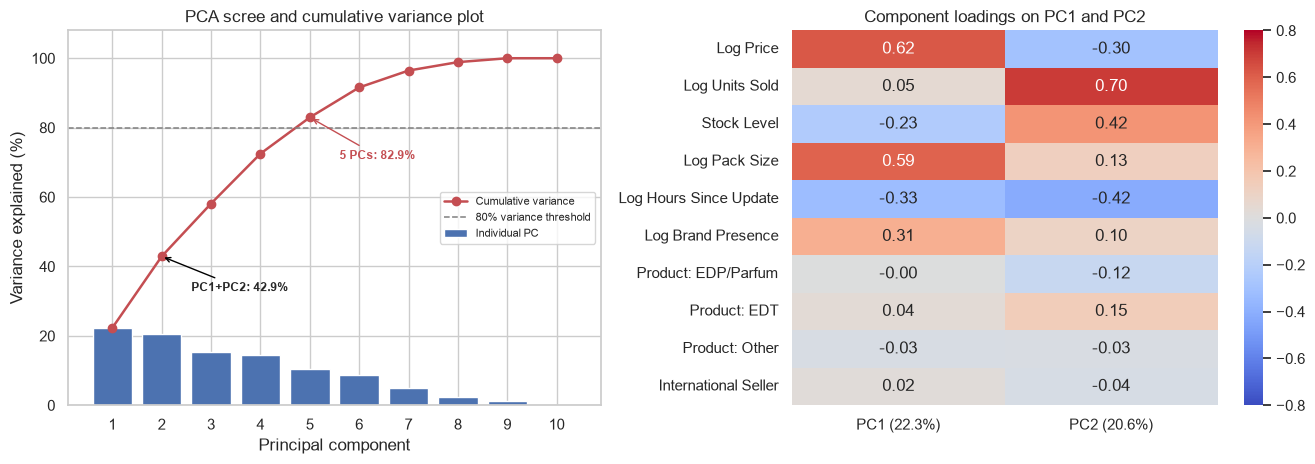

PCs for >=80% variance: 5 of 10 (82.9%). PC1+PC2 = 42.9% -> visualisation only.


In [6]:
pca = PCA(random_state=RS).fit(X)
cum_var = np.cumsum(pca.explained_variance_ratio_)
pcs_80 = int(np.argmax(cum_var >= 0.80) + 1)
pc1_pct = float(pca.explained_variance_ratio_[0] * 100)
pc2_pct = float(pca.explained_variance_ratio_[1] * 100)
pc12_pct = float(cum_var[1] * 100)
pc_80_pct = float(cum_var[pcs_80 - 1] * 100)

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8))
comps = np.arange(1, len(cum_var) + 1)
axes[0].bar(comps, pca.explained_variance_ratio_ * 100, color='C0', label='Individual PC')
axes[0].plot(comps, cum_var * 100, 'o-', color='C3', lw=1.8, label='Cumulative variance')
axes[0].axhline(80, ls='--', color='grey', lw=1.1, label='80% variance threshold')
axes[0].annotate(f'PC1+PC2: {pc12_pct:.1f}%', xy=(2, pc12_pct), xytext=(2.6, pc12_pct - 10),
                 arrowprops=dict(arrowstyle='->', color='black', lw=1.0), fontsize=8.5, fontweight='bold')
axes[0].annotate(f'{pcs_80} PCs: {pc_80_pct:.1f}%', xy=(pcs_80, pc_80_pct), xytext=(pcs_80 + 0.6, pc_80_pct - 12),
                 arrowprops=dict(arrowstyle='->', color='C3', lw=1.0), fontsize=8.5, fontweight='bold', color='C3')
axes[0].set_xticks(comps)
axes[0].set_xlabel('Principal component')
axes[0].set_ylabel('Variance explained (%)')
axes[0].set_ylim(0, 108)
axes[0].set_title('PCA scree and cumulative variance plot')
axes[0].legend(loc='center right', fontsize=8)

loadings = pd.DataFrame(pca.components_[:2].T, index=pretty_all, columns=[f'PC1 ({pc1_pct:.1f}%)', f'PC2 ({pc2_pct:.1f}%)'])
sns.heatmap(loadings, annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-0.8, vmax=0.8, ax=axes[1])
axes[1].grid(False)
axes[1].set_title('Component loadings on PC1 and PC2')
fig.tight_layout()
fig.savefig(CHART_DIR / '05_pca_scree_loadings.png', dpi=200, bbox_inches='tight')
plt.show()
plt.close(fig)

print(f'PCs for >=80% variance: {pcs_80} of {len(cum_var)} ({pc_80_pct:.1f}%). PC1+PC2 = {pc12_pct:.1f}% -> visualisation only.')
X2 = PCA(n_components=2, random_state=RS).fit_transform(X)

## A.7 Clustering models across three algorithm families

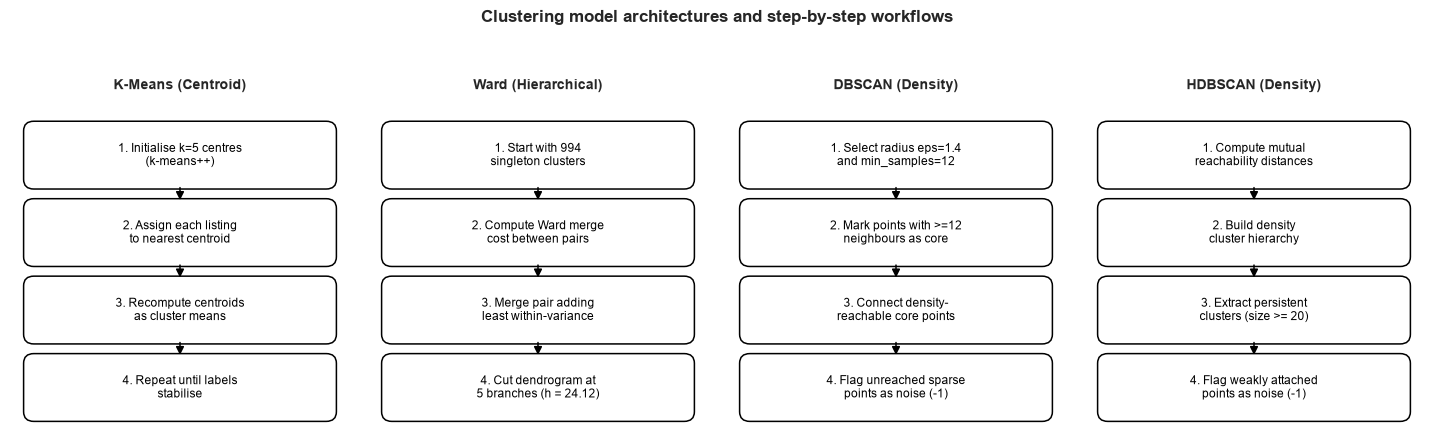

,inertia,silhouette,davies_bouldin,calinski_harabasz
k,,,,
2,5691.5,0.322,1.219,167.5
3,4797.6,0.182,1.803,191.6
4,4213.2,0.175,1.689,191.1
5,3811.7,0.167,1.608,184.3
6,3556.9,0.176,1.569,172.0
7,3334.3,0.170,1.573,163.7
8,3116.7,0.181,1.505,159.8
9,2996.3,0.174,1.501,150.3
10,2883.1,0.174,1.509,143.0


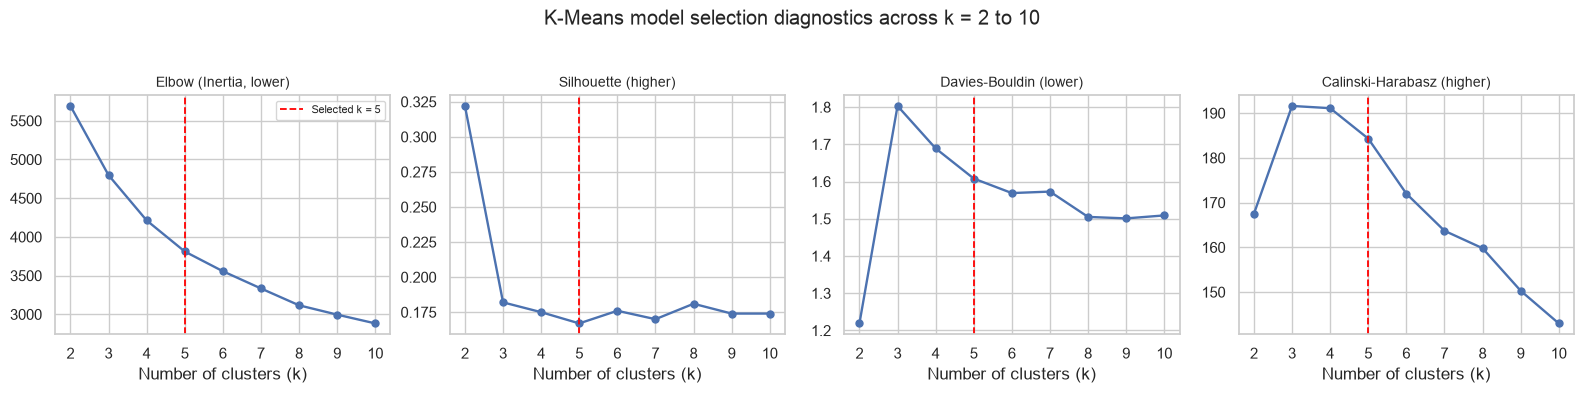

Ward cophenetic correlation: 0.524 | 5-cluster cut height: 24.12 (verified 5 clusters)
Linkage check [ward    , k=5] -> sil=0.107, largest_cluster=33.3%
Linkage check [complete, k=5] -> sil=0.061, largest_cluster=49.1%
Linkage check [single  , k=5] -> sil=0.072, largest_cluster=99.6%


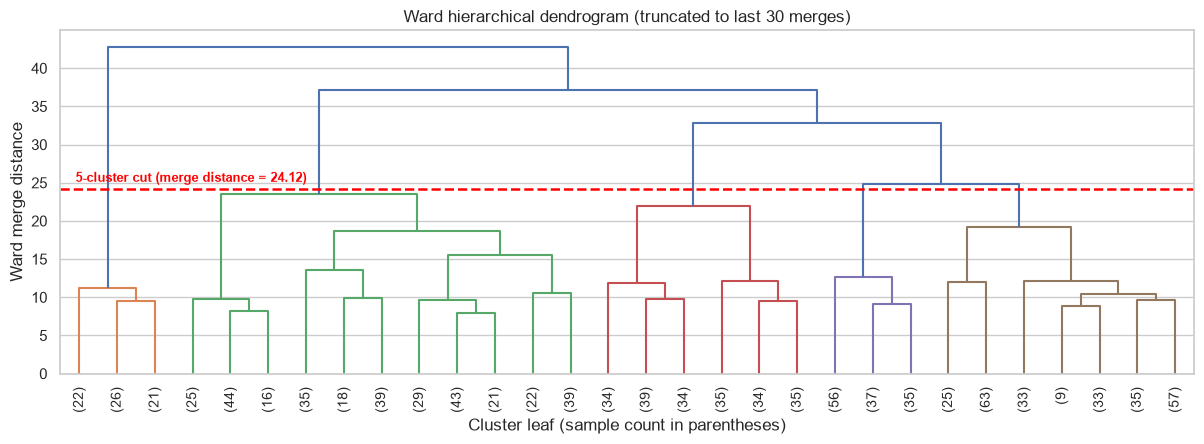

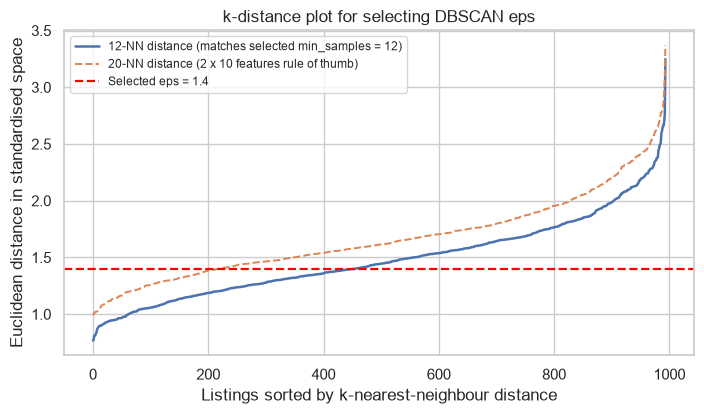

,eps,min_samples,n_clusters,noise_share,silhouette_excl_noise
14,1.4,12,3,0.251,0.096
13,1.4,8,7,0.179,-0.027
12,1.4,5,10,0.112,-0.040
8,1.2,5,10,0.226,-0.040


Chosen DBSCAN: {'eps': 1.4, 'min_samples': 12} | cluster sizes (-1 = noise): {-1: 249, 0: 291, 1: 411, 2: 43}


,min_cluster_size,min_samples,n_clusters,noise_share,silhouette_excl_noise
2,20,5,4,0.231,0.113
4,30,5,3,0.254,0.099
0,10,5,5,0.217,0.023


Chosen HDBSCAN: {'min_cluster_size': 20, 'min_samples': 5} | cluster sizes (-1 = noise): {-1: 230, 0: 22, 1: 43, 2: 283, 3: 416}


In [7]:
# Chart 6: Plain neutral workflow diagram of the four clustering models
workflow_steps = {
    'K-Means (Centroid)': [
        '1. Initialise k=5 centres\n(k-means++)',
        '2. Assign each listing\nto nearest centroid',
        '3. Recompute centroids\nas cluster means',
        '4. Repeat until labels\nstabilise',
    ],
    'Ward (Hierarchical)': [
        '1. Start with 994\nsingleton clusters',
        '2. Compute Ward merge\ncost between pairs',
        '3. Merge pair adding\nleast within-variance',
        '4. Cut dendrogram at\n5 branches (h = 24.12)',
    ],
    'DBSCAN (Density)': [
        '1. Select radius eps=1.4\nand min_samples=12',
        '2. Mark points with >=12\nneighbours as core',
        '3. Connect density-\nreachable core points',
        '4. Flag unreached sparse\npoints as noise (-1)',
    ],
    'HDBSCAN (Density)': [
        '1. Compute mutual\nreachability distances',
        '2. Build density\ncluster hierarchy',
        '3. Extract persistent\nclusters (size >= 20)',
        '4. Flag weakly attached\npoints as noise (-1)',
    ],
}
fig, axes = plt.subplots(1, 4, figsize=(14.5, 4.4))
for ax, (title, steps_txt) in zip(axes, workflow_steps.items()):
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.axis('off')
    ax.set_title(title, fontsize=10, fontweight='bold', pad=8)
    y_positions = [0.83, 0.59, 0.35, 0.11]
    for idx, (y_pos, txt) in enumerate(zip(y_positions, steps_txt)):
        box = mpatches.FancyBboxPatch(
            (0.06, y_pos - 0.085), 0.88, 0.17,
            boxstyle='round,pad=0.02,rounding_size=0.03',
            facecolor='white', edgecolor='black', linewidth=1.1,
        )
        ax.add_patch(box)
        ax.text(0.50, y_pos, txt, ha='center', va='center', fontsize=8.3, color='black')
        if idx < len(y_positions) - 1:
            ax.annotate('', xy=(0.50, y_positions[idx + 1] + 0.092), xytext=(0.50, y_pos - 0.092),
                        arrowprops=dict(arrowstyle='-|>', color='black', lw=1.1))
fig.suptitle('Clustering model architectures and step-by-step workflows', fontsize=12, fontweight='bold')
fig.tight_layout(rect=[0, 0, 1, 0.94])
fig.savefig(CHART_DIR / '06_clustering_workflows.png', dpi=200, bbox_inches='tight')
plt.show()
plt.close(fig)

# 7.1 Centroid-based: K-Means scan for k = 2 to 10
km_rows = []
for k in range(2, 11):
    km = KMeans(k, n_init=20, random_state=RS).fit(X)
    km_rows.append({
        'k': k,
        'inertia': round(float(km.inertia_), 1),
        'silhouette': round(float(silhouette_score(X, km.labels_)), 3),
        'davies_bouldin': round(float(davies_bouldin_score(X, km.labels_)), 3),
        'calinski_harabasz': round(float(calinski_harabasz_score(X, km.labels_)), 1),
    })
km_tab = pd.DataFrame(km_rows).set_index('k')
display(km_tab)

fig, axes = plt.subplots(1, 4, figsize=(16, 3.8))
metrics_spec = [
    ('inertia', 'Elbow (Inertia, lower)'),
    ('silhouette', 'Silhouette (higher)'),
    ('davies_bouldin', 'Davies-Bouldin (lower)'),
    ('calinski_harabasz', 'Calinski-Harabasz (higher)'),
]
for ax, (col, ttl) in zip(axes, metrics_spec):
    ax.plot(km_tab.index, km_tab[col], 'o-', color='C0', lw=1.7, markersize=5)
    ax.axvline(5, color='red', ls='--', lw=1.3, label='Selected k = 5')
    ax.set_title(ttl, fontsize=10)
    ax.set_xlabel('Number of clusters (k)')
    ax.set_xticks(range(2, 11))
axes[0].legend(loc='upper right', fontsize=8)
fig.suptitle('K-Means model selection diagnostics across k = 2 to 10', y=1.03)
fig.tight_layout()
fig.savefig(CHART_DIR / '07_kmeans_diagnostics.png', dpi=200, bbox_inches='tight')
plt.show()
plt.close(fig)

# 7.2 Connectivity-based: Ward hierarchical clustering
Z = linkage(X, method='ward')
d_p = pdist(X)
ward_coph = float(cophenet(Z, d_p)[0])
cut_h = float(0.5 * (Z[-5, 2] + Z[-4, 2]))
fc_check = fcluster(Z, t=cut_h, criterion='distance')
assert len(set(fc_check)) == 5, f'Expected 5 Ward clusters at cut_h={cut_h:.2f}, got {len(set(fc_check))}'
print(f'Ward cophenetic correlation: {ward_coph:.3f} | 5-cluster cut height: {cut_h:.2f} (verified {len(set(fc_check))} clusters)')

# Internal linkage check (documents why single and complete linkages are not used as final comparators)
for method in ['ward', 'complete', 'single']:
    lab_chk = AgglomerativeClustering(5, linkage=method).fit_predict(X)
    print(f'Linkage check [{method:8s}, k=5] -> sil={silhouette_score(X, lab_chk):.3f}, '
          f'largest_cluster={np.bincount(lab_chk).max()/len(lab_chk):.1%}')

fig, ax = plt.subplots(figsize=(12.2, 4.6))
dendrogram(Z, truncate_mode='lastp', p=30, leaf_rotation=90, color_threshold=cut_h, ax=ax)
ax.axhline(cut_h, color='red', ls='--', lw=1.8)
ax.text(ax.get_xlim()[0] + 4, cut_h + 1.0, f'5-cluster cut (merge distance = {cut_h:.2f})',
        color='red', fontsize=9.5, fontweight='bold')
ax.grid(axis='x', visible=False)
ax.set_title('Ward hierarchical dendrogram (truncated to last 30 merges)')
ax.set_xlabel('Cluster leaf (sample count in parentheses)')
ax.set_ylabel('Ward merge distance')
fig.tight_layout()
fig.savefig(CHART_DIR / '08_ward_dendrogram.png', dpi=200, bbox_inches='tight')
plt.show()
plt.close(fig)

# 7.3 Density-based: DBSCAN and HDBSCAN
nn_12 = NearestNeighbors(n_neighbors=12).fit(X)
kdist_12 = np.sort(nn_12.kneighbors(X)[0][:, -1])
nn_20 = NearestNeighbors(n_neighbors=20).fit(X)
kdist_20 = np.sort(nn_20.kneighbors(X)[0][:, -1])

fig, ax = plt.subplots(figsize=(7.2, 4.3))
ax.plot(kdist_12, color='C0', lw=1.8, label='12-NN distance (matches selected min_samples = 12)')
ax.plot(kdist_20, color='C1', lw=1.4, ls='--', label='20-NN distance (2 x 10 features rule of thumb)')
ax.axhline(1.4, color='red', ls='--', lw=1.6, label='Selected eps = 1.4')
ax.set_xlabel('Listings sorted by k-nearest-neighbour distance')
ax.set_ylabel('Euclidean distance in standardised space')
ax.set_title('k-distance plot for selecting DBSCAN eps')
ax.legend(loc='upper left', fontsize=8.5)
fig.tight_layout()
fig.savefig(CHART_DIR / '09_dbscan_kdistance.png', dpi=200, bbox_inches='tight')
plt.show()
plt.close(fig)

db_rows = []
for eps in [0.8, 1.0, 1.2, 1.4, 1.6, 2.0]:
    for ms in [5, 8, 12, 20]:
        lab = DBSCAN(eps=eps, min_samples=ms).fit_predict(X)
        k_found = len(set(lab)) - (1 if -1 in lab else 0)
        m = lab != -1
        sil = silhouette_score(X[m], lab[m]) if k_found > 1 else np.nan
        db_rows.append([eps, ms, k_found, (~m).mean(), sil])
db_tab = pd.DataFrame(db_rows, columns=['eps', 'min_samples', 'n_clusters', 'noise_share', 'silhouette_excl_noise'])
ok_db = db_tab[(db_tab.n_clusters >= 3) & (db_tab.noise_share <= 0.30)].sort_values('silhouette_excl_noise', ascending=False)
display(ok_db.head(5).round(3))
best_db = ok_db.iloc[0]
db_labels = DBSCAN(eps=float(best_db.eps), min_samples=int(best_db.min_samples)).fit_predict(X)
print('Chosen DBSCAN:', dict(eps=float(best_db.eps), min_samples=int(best_db.min_samples)),
      '| cluster sizes (-1 = noise):', {int(k): int(v) for k, v in zip(*np.unique(db_labels, return_counts=True))})

hdb_rows = []
for mcs in [10, 20, 30, 50]:
    for ms in [5, 10]:
        lab = HDBSCAN(min_cluster_size=mcs, min_samples=ms).fit_predict(X)
        m = lab != -1
        k_found = len(set(lab[m]))
        sil = silhouette_score(X[m], lab[m]) if k_found > 1 else np.nan
        hdb_rows.append([mcs, ms, k_found, (~m).mean(), sil])
hdb_tab = pd.DataFrame(hdb_rows, columns=['min_cluster_size', 'min_samples', 'n_clusters', 'noise_share', 'silhouette_excl_noise'])
ok_h = hdb_tab[(hdb_tab.n_clusters >= 3) & (hdb_tab.noise_share <= 0.30)].sort_values('silhouette_excl_noise', ascending=False)
display(ok_h.head(5).round(3))
best_h = ok_h.iloc[0]
hdb_labels = HDBSCAN(min_cluster_size=int(best_h.min_cluster_size), min_samples=int(best_h.min_samples)).fit_predict(X)
print('Chosen HDBSCAN:', dict(min_cluster_size=int(best_h.min_cluster_size), min_samples=int(best_h.min_samples)),
      '| cluster sizes (-1 = noise):', {int(k): int(v) for k, v in zip(*np.unique(hdb_labels, return_counts=True))})

## A.8 Model evaluation and comparison (four retained models)

,family,clusters,noise_pct,silhouette,davies_bouldin,calinski_harabasz,largest_cluster_pct
model,,,,,,,
K-Means (k=5),Centroid,5,0.0,0.167,1.608,184.3,27.2
Ward (k=5),Connectivity,5,0.0,0.107,1.720,144.0,33.3
"HDBSCAN (mcs=20, ms=5)",Density,4,23.1,0.113,1.868,81.9,54.5
"DBSCAN (eps=1.4, ms=12)",Density,3,25.1,0.096,2.227,71.9,55.2


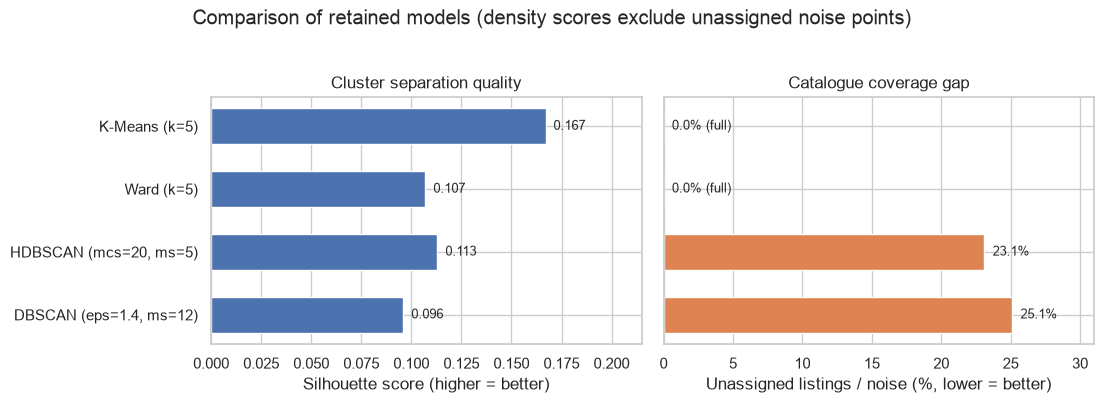

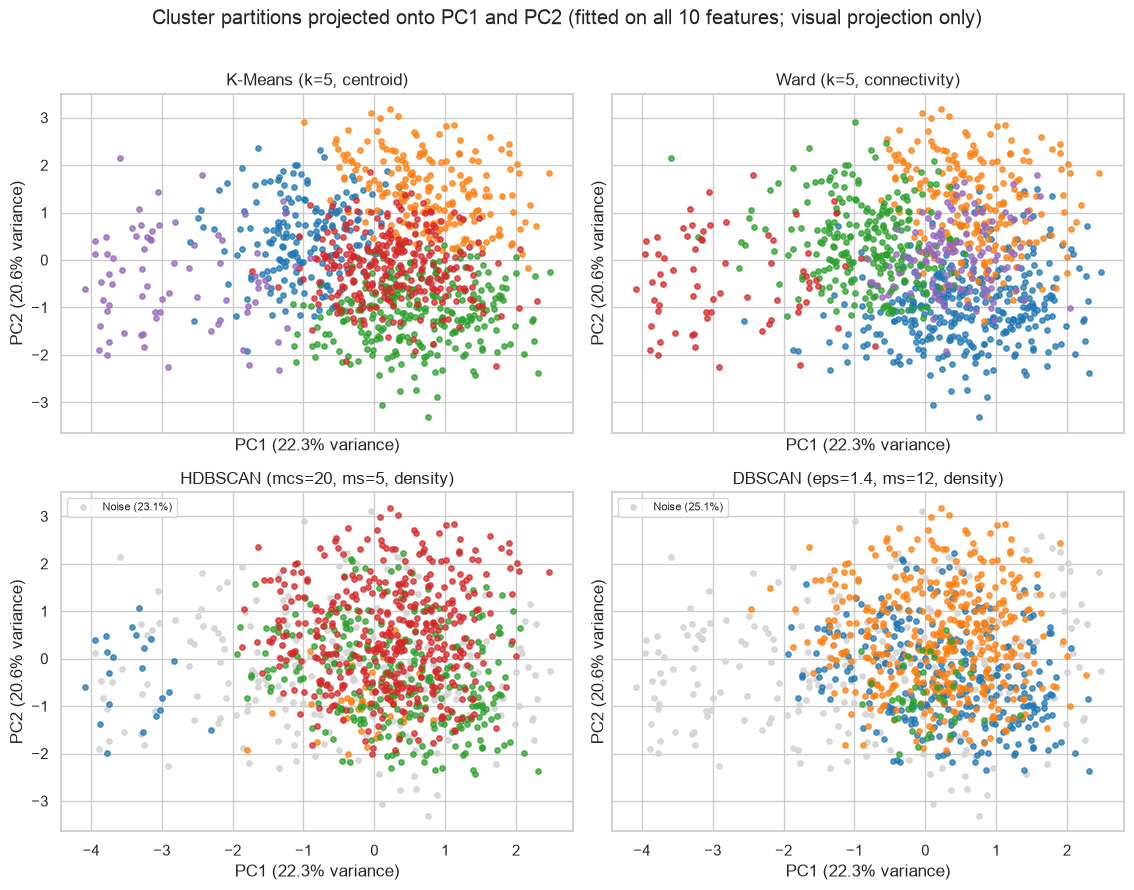

In [8]:
K = 5
km5 = KMeans(K, n_init=20, random_state=RS).fit(X)
km_labels = km5.labels_
ward_labels = AgglomerativeClustering(K, linkage='ward').fit_predict(X)


def evaluate_model(name, family, lab):
    m = lab != -1
    k_eff = len(set(lab[m]))
    return {
        'model': name,
        'family': family,
        'clusters': int(k_eff),
        'noise_pct': round(float((~m).mean() * 100), 1),
        'silhouette': round(float(silhouette_score(X[m], lab[m])), 3),
        'davies_bouldin': round(float(davies_bouldin_score(X[m], lab[m])), 3),
        'calinski_harabasz': round(float(calinski_harabasz_score(X[m], lab[m])), 1),
        'largest_cluster_pct': round(float(np.bincount(lab[m]).max() / m.sum() * 100), 1),
    }


comp = pd.DataFrame([
    evaluate_model('K-Means (k=5)', 'Centroid', km_labels),
    evaluate_model('Ward (k=5)', 'Connectivity', ward_labels),
    evaluate_model('HDBSCAN (mcs=20, ms=5)', 'Density', hdb_labels),
    evaluate_model('DBSCAN (eps=1.4, ms=12)', 'Density', db_labels),
]).set_index('model')
display(comp)

# Chart 10: Model quality and unassigned share comparison (consistent 1 -> 4 rank order)
fig, axes = plt.subplots(1, 2, figsize=(11.2, 3.9))
order_models = ['K-Means (k=5)', 'Ward (k=5)', 'HDBSCAN (mcs=20, ms=5)', 'DBSCAN (eps=1.4, ms=12)']
sil_vals = [comp.loc[m, 'silhouette'] for m in order_models]
noise_vals = [comp.loc[m, 'noise_pct'] for m in order_models]

y_pos = np.arange(len(order_models))[::-1]
axes[0].barh(y_pos, sil_vals, color='C0', height=0.58)
axes[0].set_yticks(y_pos)
axes[0].set_yticklabels(order_models)
axes[0].set_xlim(0, 0.215)
axes[0].set_xlabel('Silhouette score (higher = better)')
axes[0].set_title('Cluster separation quality')
for y, v in zip(y_pos, sil_vals):
    axes[0].text(v + 0.004, y, f'{v:.3f}', va='center', fontsize=9)

axes[1].barh(y_pos, noise_vals, color='C1', height=0.58)
axes[1].set_yticks(y_pos)
axes[1].set_yticklabels(['' for _ in order_models])
axes[1].set_xlim(0, 31)
axes[1].set_xlabel('Unassigned listings / noise (%, lower = better)')
axes[1].set_title('Catalogue coverage gap')
for y, v in zip(y_pos, noise_vals):
    axes[1].text(v + 0.6, y, f'{v:.1f}%' if v > 0 else '0.0% (full)', va='center', fontsize=9)

fig.suptitle('Comparison of retained models (density scores exclude unassigned noise points)', y=1.03)
fig.tight_layout()
fig.savefig(CHART_DIR / '10_model_comparison.png', dpi=200, bbox_inches='tight')
plt.show()
plt.close(fig)

# Chart 11: 2x2 PCA projection panel of the four retained clustering models
tab10 = plt.get_cmap('tab10')
panels = [
    ('K-Means (k=5, centroid)', km_labels),
    ('Ward (k=5, connectivity)', ward_labels),
    ('HDBSCAN (mcs=20, ms=5, density)', hdb_labels),
    ('DBSCAN (eps=1.4, ms=12, density)', db_labels),
]
fig, axes = plt.subplots(2, 2, figsize=(11.5, 8.8), sharex=True, sharey=True)
for ax, (title_txt, lab) in zip(axes.ravel(), panels):
    m = lab != -1
    if (~m).any():
        ax.scatter(X2[~m, 0], X2[~m, 1], c='lightgrey', s=15, alpha=0.85, label=f'Noise ({(~m).mean():.1%})')
    for cid in sorted(set(lab[m])):
        mask_c = lab == cid
        ax.scatter(X2[mask_c, 0], X2[mask_c, 1], color=tab10(cid % 10), s=15, alpha=0.75)
    ax.set_title(title_txt)
    ax.set_xlabel(f'PC1 ({pc1_pct:.1f}% variance)')
    ax.set_ylabel(f'PC2 ({pc2_pct:.1f}% variance)')
    if (~m).any():
        ax.legend(loc='upper left', fontsize=8, frameon=True)
fig.suptitle('Cluster partitions projected onto PC1 and PC2 (fitted on all 10 features; visual projection only)', y=1.01)
fig.tight_layout()
fig.savefig(CHART_DIR / '11_pca_clusters_2x2.png', dpi=200, bbox_inches='tight')
plt.show()
plt.close(fig)

## A.9 Stability analysis, k selection, and sensitivity checks

,mean_ari,sd_ari
k,,
3,0.478,0.333
4,0.749,0.153
5,0.755,0.118
6,0.625,0.120
7,0.575,0.111


--- K-Means k = 4 ---


,listings,median_price,median_sold,mean_stock,median_brand_listings,median_volume
l,,,,,,
3,324,50.0,18.5,3.3,10.0,100.5
0,75,16.0,24.0,7.1,9.0,3.0
1,369,31.0,51.0,9.5,9.0,100.5
2,226,36.3,509.5,7.8,17.0,100.5


--- K-Means k = 5 ---


,listings,median_price,median_sold,mean_stock,median_brand_listings,median_volume
l,,,,,,
2,270,54.2,16.0,3.1,8.0,100.0
4,74,16.0,24.5,7.1,9.5,3.0
3,270,45.0,35.0,8.9,34.0,100.5
0,186,20.0,148.0,8.9,3.0,100.5
1,194,35.5,569.5,7.4,16.0,100.5


--- K-Means k = 6 ---


,listings,median_price,median_sold,mean_stock,median_brand_listings,median_volume
l,,,,,,
4,241,55.0,13.0,3.3,8.0,100.0
2,72,16.0,27.5,7.1,10.5,2.8
1,261,43.4,37.0,8.9,34.0,100.5
0,179,20.0,131.0,9.3,4.0,100.5
3,140,36.5,291.0,9.4,15.0,100.5
5,101,36.5,677.0,2.5,15.0,100.5


Per-cluster mean silhouette (k=5): {'Best Sellers': 0.141, 'Budget Long-Tail': 0.179, 'Established-Brand Core': 0.163, 'Minis & Samples': 0.296, 'Premium Slow-Movers': 0.148}


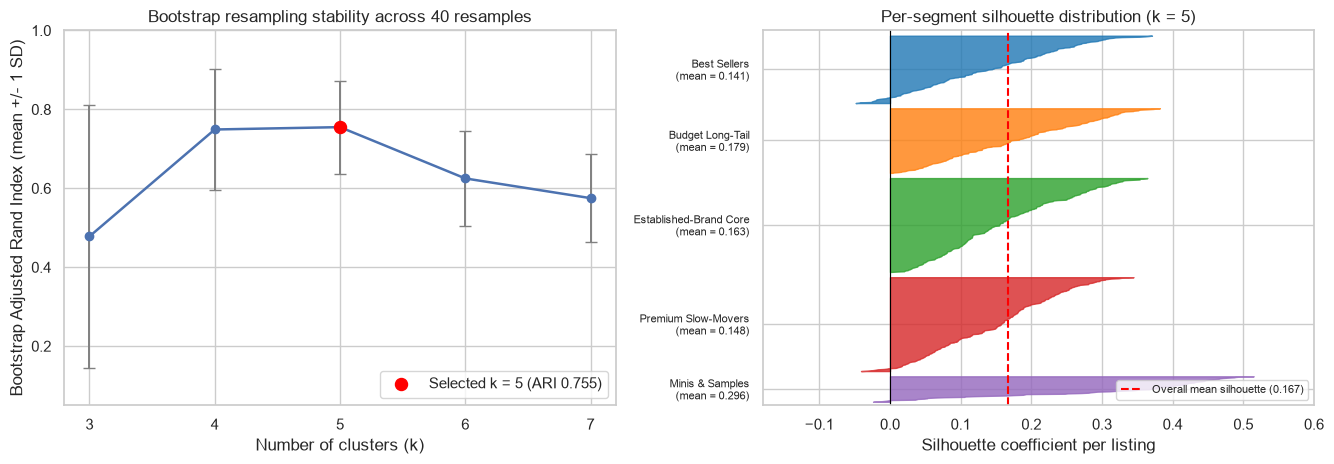

,sensitivity_test,ari_vs_baseline,silhouette
0,CAD/USD rate = 0.70,0.990,0.168
1,CAD/USD rate = 0.78,0.967,0.168
2,Limited quantity = 3,0.965,0.170
3,Linear volume_ml (unlogged),0.873,0.152
4,Numeric features only (X_num),0.846,0.193
5,UTC multi-month timestamps + brand aliases,0.761,0.164


In [9]:
def bootstrap_stability(k_val, n_boot=40):
    ref_lab = KMeans(k_val, n_init=20, random_state=RS).fit(X).labels_
    rng = np.random.default_rng(0)
    aris = []
    for _ in range(n_boot):
        idx = rng.choice(len(X), len(X), replace=True)
        boot_lab = KMeans(k_val, n_init=5, random_state=1).fit(X[idx]).predict(X)
        aris.append(adjusted_rand_score(ref_lab, boot_lab))
    return float(np.mean(aris)), float(np.std(aris))


stab_rows = []
for k_val in range(3, 8):
    mean_ari, sd_ari = bootstrap_stability(k_val, n_boot=40)
    stab_rows.append({'k': k_val, 'mean_ari': round(mean_ari, 3), 'sd_ari': round(sd_ari, 3)})
stab_df = pd.DataFrame(stab_rows).set_index('k')
display(stab_df)

# Inspect k = 4, 5, 6 segment splits and capture the k = 6 low-stock high-seller sub-group
k6_low_stock_info = {}
for k_val in (4, 5, 6):
    lab_k = KMeans(k_val, n_init=20, random_state=RS).fit_predict(X)
    t_k = df.assign(l=lab_k).groupby('l').agg(
        listings=('price_usd', 'size'),
        median_price=('price_usd', 'median'),
        median_sold=('sold_c', 'median'),
        mean_stock=('stock', 'mean'),
        median_brand_listings=('brand_listings', 'median'),
        median_volume=('volume_ml', 'median'),
    )
    print(f'--- K-Means k = {k_val} ---')
    display(t_k.sort_values('median_sold').round(1))
    if k_val == 6:
        top_seller_k6 = t_k.loc[t_k['median_sold'].idxmax()]
        k6_low_stock_info = {
            'listings': int(top_seller_k6['listings']),
            'median_sold': int(round(top_seller_k6['median_sold'])),
            'mean_stock': round(float(top_seller_k6['mean_stock']), 1),
        }

# Compute rule-based segment names early so silhouette diagram shows real segment names
df['cluster'] = km_labels
df['revenue_proxy'] = df.price_usd * df.sold_c

prof = df.groupby('cluster').agg(
    listings=('price_usd', 'size'),
    median_price=('price_usd', 'median'),
    iqr_price=('price_usd', lambda s: s.quantile(0.75) - s.quantile(0.25)),
    median_units_sold=('sold_c', 'median'),
    iqr_units_sold=('sold_c', lambda s: s.quantile(0.75) - s.quantile(0.25)),
    mean_stock=('stock', 'mean'),
    median_volume_ml=('volume_ml', 'median'),
    median_hours_since_update=('hours_since', 'median'),
    median_brand_listings=('brand_listings', 'median'),
    pct_international=('international', 'mean'),
    pct_EDT=('product_type', lambda s: (s == 'EDT').mean()),
    pct_EDP=('product_type', lambda s: (s == 'EDP/Parfum').mean()),
)
prof['share_of_listings_%'] = prof.listings / prof.listings.sum() * 100
prof['share_of_sales_value_%'] = df.groupby('cluster').revenue_proxy.sum() / df.revenue_proxy.sum() * 100

names = {}
names[prof.median_volume_ml.idxmin()] = 'Minis & Samples'
rest = prof.drop(index=list(names))
names[rest.median_units_sold.idxmax()] = 'Best Sellers'
rest = prof.drop(index=list(names))
names[rest.median_brand_listings.idxmin()] = 'Budget Long-Tail'
rest = prof.drop(index=list(names))
names[rest.median_price.idxmax()] = 'Premium Slow-Movers'
names[[c_id for c_id in prof.index if c_id not in names][0]] = 'Established-Brand Core'

df['segment'] = df.cluster.map(names)
prof.insert(0, 'segment', prof.index.map(names))
prof = prof.sort_values('share_of_sales_value_%', ascending=False)
seg_order = list(prof.segment)
seg_color_map = {seg: tab10(i) for i, seg in enumerate(seg_order)}

# Per-cluster silhouette scores
sil_vals_all = silhouette_samples(X, km_labels)
df['silhouette_sample'] = sil_vals_all
per_cluster_sil = df.groupby('segment')['silhouette_sample'].mean().round(3).to_dict()
print('Per-cluster mean silhouette (k=5):', per_cluster_sil)

# Chart 12: Bootstrap stability (k=3..7) and per-cluster silhouette plot (k=5)
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8))
axes[0].errorbar(
    stab_df.index, stab_df['mean_ari'], yerr=stab_df['sd_ari'],
    fmt='o-', color='C0', ecolor='grey', elinewidth=1.4, capsize=4, lw=1.8,
)
axes[0].scatter([5], [stab_df.loc[5, 'mean_ari']], color='red', s=75, zorder=5,
                label=f"Selected k = 5 (ARI {stab_df.loc[5, 'mean_ari']:.3f})")
axes[0].set_xticks(range(3, 8))
axes[0].set_ylim(0.05, 1.0)
axes[0].set_xlabel('Number of clusters (k)')
axes[0].set_ylabel('Bootstrap Adjusted Rand Index (mean +/- 1 SD)')
axes[0].set_title('Bootstrap resampling stability across 40 resamples')
axes[0].legend(loc='lower right')

y_lower = 10
y_centers = []
y_labels = []
for seg in reversed(seg_order):
    vals = np.sort(df.loc[df.segment == seg, 'silhouette_sample'].to_numpy())
    y_upper = y_lower + len(vals)
    col = seg_color_map[seg]
    axes[1].fill_betweenx(np.arange(y_lower, y_upper), 0, vals, facecolor=col, edgecolor=col, alpha=0.8)
    y_centers.append(y_lower + 0.5 * len(vals))
    y_labels.append(f'{seg}\n(mean = {vals.mean():.3f})')
    y_lower = y_upper + 14

global_sil = float(comp.loc['K-Means (k=5)', 'silhouette'])
axes[1].axvline(global_sil, color='red', ls='--', lw=1.5, label=f'Overall mean silhouette ({global_sil:.3f})')
axes[1].axvline(0, color='black', lw=0.8)
axes[1].set_xlim(min(-0.18, float(sil_vals_all.min()) - 0.03), 0.60)
axes[1].set_ylim(0, y_lower)
axes[1].set_yticks(y_centers)
axes[1].set_yticklabels(y_labels, fontsize=8)
axes[1].set_xlabel('Silhouette coefficient per listing')
axes[1].set_title('Per-segment silhouette distribution (k = 5)')
axes[1].legend(loc='lower right', fontsize=8)
fig.tight_layout()
fig.savefig(CHART_DIR / '12_stability_silhouette.png', dpi=200, bbox_inches='tight')
plt.show()
plt.close(fig)

# Sensitivity and assumption robustness checks against baseline K-Means k=5
def build_variant_matrix(cad_rate=0.73, limited_val=2, log_vol=True, use_dummies=True, full_ts_brands=False):
    v = raw.copy()
    p_s = v['priceWithCurrency'].str.extract(r'([\d,]+\.?\d*)')[0].str.replace(',', '').astype(float)
    p = v.price.fillna(p_s)
    v['price_usd'] = np.where(v['priceWithCurrency'].fillna('').str.startswith('C $'), p * cad_rate, p)
    s_s = v.text.fillna('').str.extract(r'/ ([\d,]+) sold')[0].str.replace(',', '').astype(float)
    v['sold_c'] = v.sold.fillna(s_s)
    tk = v.text.fillna('')
    stk = tk.str.extract(r'^(?:More than )?(\d+)(?: lots)? available')[0].astype(float)
    stk = np.where(tk.str.startswith('Last One'), 1, stk)
    stk = np.where(tk.str.startswith('Limited'), limited_val, stk)
    v['stock'] = np.minimum(pd.Series(stk, index=v.index), 10).fillna(np.minimum(v.available, 10))
    desc = v.details.fillna('')
    v['volume_ml'] = desc.str.extract(r'(\d+(?:\.\d+)?)\s*ml\b', flags=re.I)[0].astype(float).fillna(
        desc.str.extract(r'(\d+(?:\.\d+)?)\s*(?:fl\.?\s*)?oz\b', flags=re.I)[0].astype(float) * 29.5735
    )
    if full_ts_brands:
        tz_offsets = {'PDT': '-0700', 'PST': '-0800'}
        def parse_full_ts(val):
            if pd.isna(val):
                return pd.NaT
            m_ts = re.match(r'^([A-Za-z]+)\s+(\d+),\s+(\d{4})\s+(\d+:\d+:\d+)\s+([A-Z]{2,4})$', str(val).strip())
            if not m_ts:
                return pd.NaT
            mon, day, yr, tm, tz = m_ts.groups()
            off = tz_offsets.get(tz, '-0700')
            for fmt in ('%B %d %Y %H:%M:%S %z', '%b %d %Y %H:%M:%S %z'):
                try:
                    return pd.to_datetime(f'{mon} {day} {yr} {tm} {off}', format=fmt, utc=True)
                except Exception:
                    pass
            return pd.NaT
        t_series = v.lastUpdated.apply(parse_full_ts)
    else:
        t_series = pd.to_datetime(
            v.lastUpdated.str.replace(r'\s[A-Z]{3}$', '', regex=True),
            format='%B %d, %Y %H:%M:%S',
            errors='coerce',
        )
    v['hours_since'] = (t_series.max() - t_series).dt.total_seconds() / 3600
    cat = v.Catatory.fillna('').str.lower()
    v['product_type'] = np.select(
        [cat.str.contains('toil'), cat.str.contains('cologne|aftershave'),
         cat.str.contains('parfum|perfume') & ~cat.str.contains('toil'), cat.str.contains('fragrance')],
        ['EDT', 'Cologne', 'EDP/Parfum', 'Fragrance'], default='Other'
    )
    v['product_type'] = v['product_type'].replace({'Cologne': 'Other', 'Fragrance': 'Other'})
    v['international'] = (v.itemLocation.str.split(',').str[-1].str.strip() != 'United States').astype(float)
    br = v.Item_Name.fillna('unknown').str.lower().str.replace(r'\s*&\s*', ' & ', regex=True).str.strip()
    if full_ts_brands:
        br = br.str.strip('~ ').replace({
            'polo ralph lauren': 'ralph lauren', 'lauren ralph lauren': 'ralph lauren',
            'christian dior': 'dior', 'as shown': 'as show', 'gianni versace': 'versace',
        })
    else:
        br = br.replace({'polo ralph lauren': 'ralph lauren'})
    v['brand_listings'] = br.map(br.value_counts())
    v = v.dropna(subset=['price_usd', 'sold_c', 'stock']).reset_index(drop=True)
    v['volume_ml'] = v['volume_ml'].clip(upper=v['volume_ml'].quantile(0.99)).fillna(v['volume_ml'].median())
    v['hours_since'] = v['hours_since'].fillna(v['hours_since'].median())
    vf = pd.DataFrame({
        'log_price': np.log1p(v.price_usd),
        'log_sold': np.log1p(v.sold_c),
        'stock': v.stock,
        'volume': np.log1p(v.volume_ml) if log_vol else v.volume_ml,
        'log_hours': np.log1p(v.hours_since),
        'log_brand_listings': np.log1p(v.brand_listings),
    })
    Xn = StandardScaler().fit_transform(vf)
    if not use_dummies:
        return Xn
    dm = pd.get_dummies(v[['product_type']]).astype(float)
    dm['international'] = v.international.values
    return np.hstack([Xn, dm.values])


sens_specs = [
    ('CAD/USD rate = 0.70', dict(cad_rate=0.70)),
    ('CAD/USD rate = 0.78', dict(cad_rate=0.78)),
    ('Limited quantity = 3', dict(limited_val=3)),
    ('Linear volume_ml (unlogged)', dict(log_vol=False)),
    ('Numeric features only (X_num)', dict(use_dummies=False)),
    ('UTC multi-month timestamps + brand aliases', dict(full_ts_brands=True)),
]
sens_rows = []
for s_name, kwargs in sens_specs:
    Xs = build_variant_matrix(**kwargs)
    ls = KMeans(5, n_init=20, random_state=RS).fit_predict(Xs)
    sens_rows.append({
        'sensitivity_test': s_name,
        'ari_vs_baseline': round(float(adjusted_rand_score(km_labels, ls)), 3),
        'silhouette': round(float(silhouette_score(Xs, ls)), 3),
    })
sens_df = pd.DataFrame(sens_rows)
display(sens_df)

## A.10 Cluster profiling and statistical validation

Kruskal-Wallis [price_usd     ]: H =  340.3, p = 2.22e-72
Kruskal-Wallis [sold_c        ]: H =  345.0, p = 2.06e-73
Kruskal-Wallis [stock         ]: H =  475.9, p = 1.11e-101
Kruskal-Wallis [volume_ml     ]: H =  248.9, p = 1.14e-52
Kruskal-Wallis [hours_since   ]: H =  387.5, p = 1.43e-82
Kruskal-Wallis [brand_listings]: H =  318.4, p = 1.14e-67


,listings,median_price,iqr_price,median_units_sold,iqr_units_sold,mean_stock,median_volume_ml,median_hours_since_update,median_brand_listings,pct_international,pct_EDT,pct_EDP,share_of_listings_%,share_of_sales_value_%
segment,,,,,,,,,,,,,,
Best Sellers,194,35.50,25.75,569.5,2004.75,7.44,100.55,2.82,16.0,0.01,0.64,0.27,19.52,74.63
Budget Long-Tail,186,19.99,14.93,148.0,574.00,8.89,100.55,63.12,3.0,0.05,0.57,0.26,18.71,10.73
Established-Brand Core,270,44.99,39.36,35.0,94.25,8.94,100.55,48.23,34.0,0.16,0.48,0.43,27.16,7.97
Premium Slow-Movers,270,54.24,52.02,16.0,36.00,3.06,100.00,36.89,8.0,0.12,0.30,0.46,27.16,5.54
Minis & Samples,74,15.99,10.72,24.5,146.25,7.08,3.00,37.82,9.5,0.00,0.23,0.66,7.44,1.13


Best Sellers             -> Ralph Lauren (17), Dolce & Gabbana (15), Giorgio Armani (12), Versace (11)
Budget Long-Tail         -> Secertmu (9), Dossier (6), Cologne (5), Nautica (4)
Established-Brand Core   -> Giorgio Armani (34), Ralph Lauren (28), Paco Rabanne (27), Unbranded (26)
Premium Slow-Movers      -> Giorgio Armani (10), Yves Saint Laurent (10), Paco Rabanne (9), Armaf (8)
Minis & Samples          -> Dolce & Gabbana (6), Creed (6), Chanel (5), Yves Saint Laurent (5)


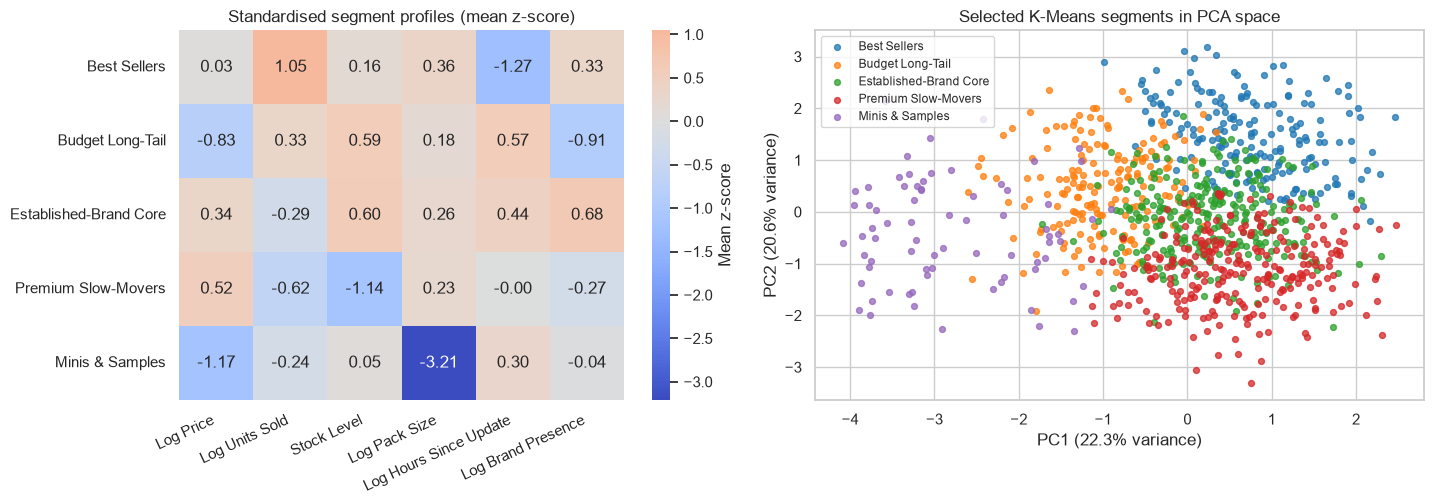

In [10]:
kw_results = {}
for col in num_cols:
    groups = [g[col].to_numpy() for _, g in df.groupby('segment')]
    h_stat, p_val = kruskal(*groups)
    kw_results[col] = {'H': round(float(h_stat), 1), 'p': float(p_val)}
    print(f'Kruskal-Wallis [{col:14s}]: H = {h_stat:6.1f}, p = {p_val:.2e}')

display(prof.round(2).set_index('segment'))

top_brands_by_segment = {}
for s in seg_order:
    g = df[df.segment == s]
    top_str = ', '.join(f'{b_name.title()} ({cnt})' for b_name, cnt in g.brand.value_counts().head(4).items())
    top_brands_by_segment[s] = top_str
    print(f'{s:24s} -> {top_str}')

# Chart 13: 2-panel segment profiles (z-score heatmap + PCA segment projection)
z_df = pd.DataFrame(X_num, columns=pretty_feat)
z_df['segment'] = df.segment.values
z_means = z_df.groupby('segment').mean().loc[seg_order]

fig, axes = plt.subplots(1, 2, figsize=(14.5, 5.2), gridspec_kw={'width_ratios': [1.05, 1.15]})
sns.heatmap(z_means, annot=True, fmt='.2f', cmap='coolwarm', center=0,
            cbar_kws={'label': 'Mean z-score'}, ax=axes[0])
axes[0].grid(False)
axes[0].set_title('Standardised segment profiles (mean z-score)')
axes[0].set_ylabel('')
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=25, ha='right')

for s in seg_order:
    mask_s = df.segment == s
    axes[1].scatter(X2[mask_s, 0], X2[mask_s, 1], s=18, alpha=0.75, color=seg_color_map[s], label=s)
axes[1].set_title('Selected K-Means segments in PCA space')
axes[1].set_xlabel(f'PC1 ({pc1_pct:.1f}% variance)')
axes[1].set_ylabel(f'PC2 ({pc2_pct:.1f}% variance)')
axes[1].legend(loc='upper left', fontsize=8.5, frameon=True)
fig.tight_layout()
fig.savefig(CHART_DIR / '13_segment_profiles.png', dpi=200, bbox_inches='tight')
plt.show()
plt.close(fig)

## A.11 Classification-based boundary recovery

,cv_accuracy,cv_macro_f1
model,,
Logistic regression,0.978,0.977
Random forest,0.930,0.937


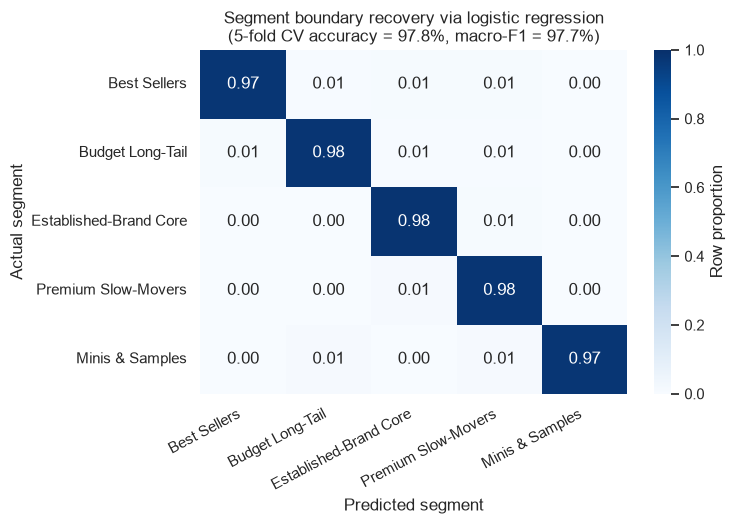

In [11]:
seg_y = df.segment.to_numpy()
bnd_models = {
    'Logistic regression': LogisticRegression(max_iter=3000),
    'Random forest': RandomForestClassifier(300, random_state=RS, n_jobs=-1),
}
bnd_rows = []
for b_name, b_mod in bnd_models.items():
    acc_b = float(cross_val_score(b_mod, X, seg_y, cv=sk).mean())
    f1_b = float(cross_val_score(b_mod, X, seg_y, cv=sk, scoring='f1_macro').mean())
    bnd_rows.append({'model': b_name, 'cv_accuracy': round(acc_b, 3), 'cv_macro_f1': round(f1_b, 3)})
bnd_tab = pd.DataFrame(bnd_rows).set_index('model')
display(bnd_tab)

pred_seg = cross_val_predict(bnd_models['Logistic regression'], X, seg_y, cv=sk)
cm_seg = pd.crosstab(
    pd.Categorical(seg_y, categories=seg_order, ordered=True),
    pd.Categorical(pred_seg, categories=seg_order, ordered=True),
    normalize='index',
)
cm_seg.index.name = 'Actual segment'
cm_seg.columns.name = 'Predicted segment'

fig, ax = plt.subplots(figsize=(7.6, 5.4))
sns.heatmap(cm_seg, annot=True, fmt='.2f', cmap='Blues', vmin=0, vmax=1,
            cbar_kws={'label': 'Row proportion'}, ax=ax)
ax.grid(False)
ax.set_title(
    f"Segment boundary recovery via logistic regression\n"
    f"(5-fold CV accuracy = {bnd_tab.loc['Logistic regression', 'cv_accuracy']:.1%}, "
    f"macro-F1 = {bnd_tab.loc['Logistic regression', 'cv_macro_f1']:.1%})"
)
plt.xticks(rotation=28, ha='right')
plt.yticks(rotation=0)
fig.tight_layout()
fig.savefig(CHART_DIR / '14_boundary_recovery.png', dpi=200, bbox_inches='tight')
plt.show()
plt.close(fig)

## A.12 Task 2 executive charts

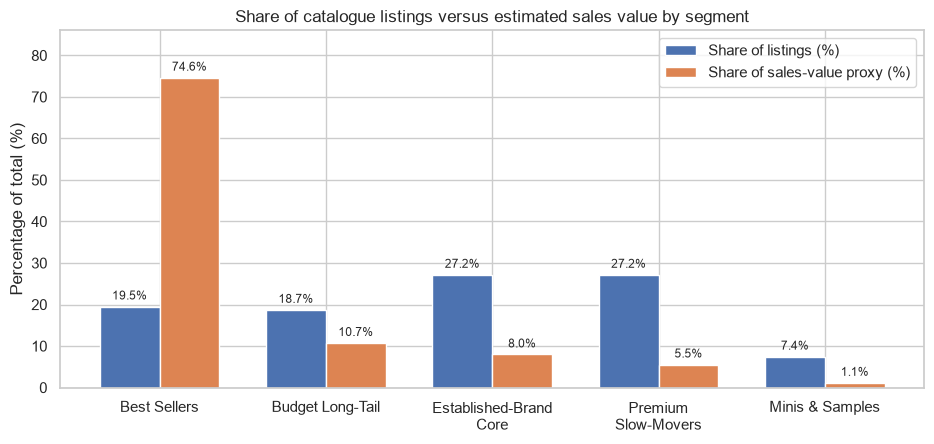

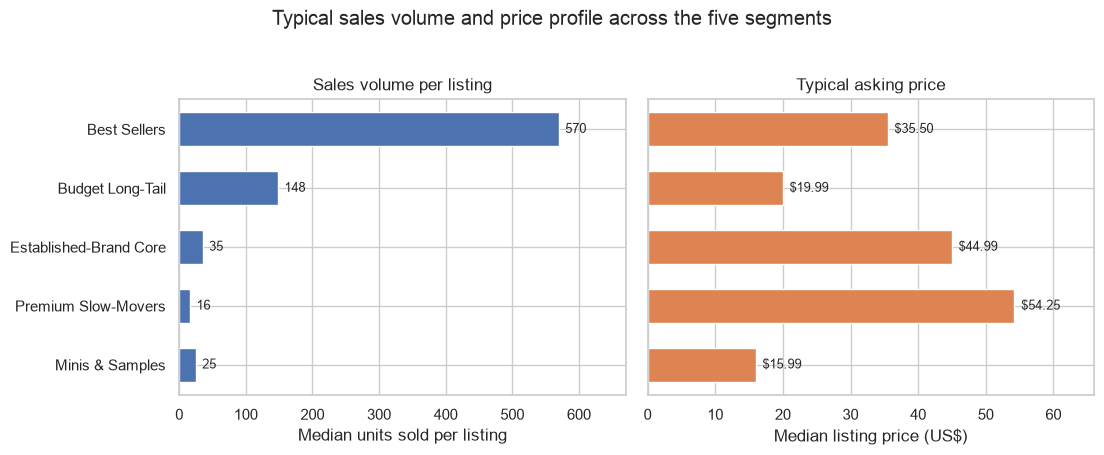

Analysis complete. Saved 16 charts to charts


In [12]:
# Chart 15: Share of listings vs share of sales-value proxy by segment
fig, ax = plt.subplots(figsize=(9.5, 4.6))
x_pos = np.arange(len(prof))
width = 0.36
b1 = ax.bar(x_pos - width / 2, prof['share_of_listings_%'], width, color='C0', label='Share of listings (%)')
b2 = ax.bar(x_pos + width / 2, prof['share_of_sales_value_%'], width, color='C1', label='Share of sales-value proxy (%)')
for bar_grp in (b1, b2):
    for bar in bar_grp:
        h = bar.get_height()
        ax.text(bar.get_x() + bar.get_width() / 2, h + 1.1, f'{h:.1f}%',
                ha='center', va='bottom', fontsize=8.3)
ax.set_xticks(x_pos)
ax.set_xticklabels([s.replace(' ', '\n', 1) if len(s) > 16 else s for s in prof['segment']])
ax.set_ylabel('Percentage of total (%)')
ax.set_ylim(0, 86)
ax.set_title('Share of catalogue listings versus estimated sales value by segment')
ax.legend(loc='upper right', frameon=True)
fig.tight_layout()
fig.savefig(CHART_DIR / '15_segment_shares.png', dpi=200, bbox_inches='tight')
plt.show()
plt.close(fig)

# Chart 16: Median units sold and median price by segment (consistent with Table 9)
prof_rev = prof.iloc[::-1].reset_index(drop=True)
fig, axes = plt.subplots(1, 2, figsize=(11.2, 4.4), sharey=True)
y_idx = np.arange(len(prof_rev))

axes[0].barh(y_idx, prof_rev['median_units_sold'], color='C0', height=0.58)
axes[0].set_yticks(y_idx)
axes[0].set_yticklabels(prof_rev['segment'])
axes[0].set_xlim(0, 670)
axes[0].set_xlabel('Median units sold per listing')
axes[0].set_title('Sales volume per listing')
for y, v in zip(y_idx, prof_rev['median_units_sold']):
    axes[0].text(v + 10, y, f'{int(np.floor(v + 0.5))}', va='center', fontsize=9)

axes[1].barh(y_idx, prof_rev['median_price'], color='C1', height=0.58)
axes[1].set_xlim(0, 66)
axes[1].set_xlabel('Median listing price (US$)')
axes[1].set_title('Typical asking price')
for y, v in zip(y_idx, prof_rev['median_price']):
    axes[1].text(v + 1.0, y, f'${v:.2f}', va='center', fontsize=9)

fig.suptitle('Typical sales volume and price profile across the five segments', y=1.03)
fig.tight_layout()
fig.savefig(CHART_DIR / '16_segment_medians.png', dpi=200, bbox_inches='tight')
plt.show()
plt.close(fig)

print('Analysis complete. Saved 16 charts to', CHART_DIR)